In [6]:
multi_lm_agent = MultiLMAgent(api_manager)

In [1]:
# Auto-reloads imported modules, so changes to .py files are automatically reflected in the notebook
%load_ext autoreload
%autoreload 2

## Importing the relevant tools.
## Make sure you installed this package with the instructions in README.md
import os
from dotenv import load_dotenv, find_dotenv

# Load environment variables from .env at the repo root (walks up from the notebook cwd).
# Refer README.md for more details. Copy `.env.example` to `.env` and add your tokens.
load_dotenv(find_dotenv())


True

## Package Installation

#### API Configuration and Setup

Before we can use the APIs, we need to set up our environment and initialize the API manager. This involves:

1. Loading API keys from environment variables
2. Setting up the API manager with the necessary credentials
3. Validating that all required keys are present

For this assignment, we'll use:
- Tavily Search API (requires API key)
     - https://www.tavily.com/
     - API description and test notebook: [tavily.ipynb](./eval-search-apis/tavily.ipynb)
- Polygon (Massive) API is a real-time and historical financial market data API (requires API key)
     - https://polygon.io/dashboard/keys
     - rebranded to massive.com
     - API description and test notebook: [polygon.ipynb](./eval-search-apis/polygon.ipynb)

- Wolfram Alpha API (requires **app ID**): 
     - https://developer.wolframalpha.com/access
     - API description and test notebook: [wolframalpha.ipynb](./eval-search-apis/wolframalpha.ipynb)

**Note**: Be mindful of your API usage and compute budget. Use smaller, more cost-effective models (e.g. `openrouter/google/gemma-3-4b-it`) for development before scaling to larger models. For security, never hardcode API keys; always use a `.env` file and add it to your `.gitignore`. See `README.md` for OpenRouter and tool API key setup.

### Model API config

We will use open-source language models through [OpenRouter](https://openrouter.ai/). See `README.md` for how to get API keys and add them to your `.env` file.

OpenRouter provides a single API to many open-source models hosted by different providers, so you do not need to set up a dedicated server. Model availability can change over time; if you cannot access a model used in this notebook, please reach out to the teaching staff.

In [2]:
from xag329a_a3.api_manager import APIManager

if not os.getenv("OPENROUTER_API_KEY"):
    raise ValueError(
        "OPENROUTER_API_KEY is not set. "
        "Copy .env.example to .env, add your OpenRouter API key "
        "(see README.md), then re-run the imports cell so load_dotenv() runs."
    )
print("OPENROUTER_API_KEY is set.")

TAVILY_API_KEY = os.getenv('TAVILY_API_KEY')
POLYGON_API_KEY = os.getenv('POLYGON_API_KEY')
WOLFRAM_APP_ID = os.getenv('WOLFRAM_APP_ID')

if not all([TAVILY_API_KEY, POLYGON_API_KEY, WOLFRAM_APP_ID]):
    raise ValueError(
        "One or more required API keys are missing from environment variables. "
        "Copy .env.example to .env, add TAVILY_API_KEY, POLYGON_API_KEY, and WOLFRAM_APP_ID "
        "(see README.md), then re-run the imports cell so load_dotenv() runs."
    )

api_manager = APIManager(
    tavily_api_key=TAVILY_API_KEY,
    polygon_api_key=POLYGON_API_KEY,
    wolfram_app_id=WOLFRAM_APP_ID
)

print("APIManager initialized successfully.")

OPENROUTER_API_KEY is set.
APIManager initialized successfully.


### Model config

In this assignment, we will use the following open-source models via OpenRouter.

Judge / cheap eval: `google/gemma-3-4b-it`

- Model page: https://openrouter.ai/google/gemma-3-4b-it

Default / routing: `meta-llama/llama-3.1-8b-instruct`

- Model page: https://openrouter.ai/meta-llama/llama-3.1-8b-instruct

Stronger single-call / decomposition / refinement: `meta-llama/llama-3.3-70b-instruct`

- Model page: https://openrouter.ai/meta-llama/llama-3.3-70b-instruct

Fusion: `meta-llama/llama-3.1-8b-instruct` and `openai/gpt-oss-20b`

- Model pages: https://openrouter.ai/meta-llama/llama-3.1-8b-instruct and https://openrouter.ai/openai/gpt-oss-20b

In [3]:
JUDGE_MODEL = "openrouter/openai/gpt-oss-20b"
DEFAULT_MODEL = "openrouter/meta-llama/llama-3.1-8b-instruct"
STRONG_MODEL = "openrouter/meta-llama/llama-3.3-70b-instruct"
FUSION_MODEL = "openrouter/meta-llama/llama-3.1-8b-instruct"
FUSION_SAMPLE_MODELS = [
    FUSION_MODEL,
    "openrouter/openai/gpt-oss-20b",
]

print(f"Judge model: {JUDGE_MODEL}")
print(f"Default model: {DEFAULT_MODEL}")
print(f"Strong model: {STRONG_MODEL}")
print(f"Fusion model: {FUSION_MODEL}")


Judge model: openrouter/openai/gpt-oss-20b
Default model: openrouter/meta-llama/llama-3.1-8b-instruct
Strong model: openrouter/meta-llama/llama-3.3-70b-instruct
Fusion model: openrouter/meta-llama/llama-3.1-8b-instruct


## Part 0 - LLM Performance with a Single Call [5 points]

To establish a baseline, let's test the performance of a standalone Large Language Model (LLM) without any external tools or APIs. This helps illustrate the limitations of relying solely on the model's internal knowledge, especially for questions requiring real-time, specific, or computational information.

**Deliverable:**
- In the [`xag329a_a3/multi_lm_agent.py`](xag329a_a3/multi_lm_agent.py) file, implement the `generate` method in the MultiLMAgent class.

**Observe that:**
- LLMs can hallucinate or provide outdated information for fact-based queries.
- Models often struggle with precise mathematical calculations that a tool like Wolfram Alpha can solve instantly, due to the tokenization scheme.
- Queries about current stock prices or today's weather are outside the scope of a model's static training data.
- Evaluation is difficult for unstructured model outputs. Numerical answers have multiple possible formats, which makes naive string-matching unreliable; and natural language answers can be phrased in various ways. To that end, we've provided a `evaluate_qa` function that uses a fast, cheap model ([`gemma-3-4b-it`](https://openrouter.ai/google/gemma-3-4b-it)) to more reliably evaluate the model's output.

You can set `DEBUG_MODE` to be `True` when developing. Change to `False` for final results.

In [4]:
DEBUG_MODE = True  # Set to True when developing, False for final results

In [4]:
from xag329a_a3.multi_lm_agent import MultiLMAgent
from xag329a_a3.evaluation import prepare_dataset, evaluate_qa

In [6]:
# Self-checks for `__init__` and `generate` (no API calls).
# These use a fake API manager and canned replies, so they cost nothing to run.
from xag329a_a3.tests import test_agent_init, test_generate

test_agent_init()
test_generate()

No errors detected for `MultiLMAgent.__init__`
Generation failed for fake/model-x.
No errors detected for `generate`


In [7]:
multi_lm_agent = MultiLMAgent(api_manager)
dataset = prepare_dataset(debug_mode=DEBUG_MODE)

queries, answers = dataset['query'], dataset['answer']
num_correct = 0
print("Zero-Shot Responses:")
zero_shot_responses = []
for query, answer in zip(queries, answers):
    response = multi_lm_agent.generate(query=query, model=DEFAULT_MODEL)
    zero_shot_responses.append(response)
    print(f"Query: {query}")
    print(f"Zero-Shot Response: {response}")
    print(f"Answer: {answer}")
    is_correct = evaluate_qa(query, response, answer, model=JUDGE_MODEL)
    num_correct += is_correct
    print("Is Correct:", is_correct)
    print("-" * 50)

accuracy_zero_shot = num_correct / len(queries)
print(f"Accuracy = {accuracy_zero_shot*100:.1f}%")

Zero-Shot Responses:


Query: Were there any thunderstorms in Seattle, WA at noon on June 1st, 2025?
Zero-Shot Response: I'm unable to provide information about future events. However, I can suggest some alternatives:

1.  **Check online weather forecasts**: You can check websites like AccuWeather, Weather.com, or the National Weather Service (NWS) for weather forecasts and historical data. They might have information about past weather conditions on June 1st, 2025.
2.  **Contact local weather services**: You can reach out to local weather services or meteorological offices in Seattle, WA, to inquire about weather conditions on that specific date. They might have access to historical data and can provide you with the information you need.
3.  **Look for historical records**: If you're interested in historical weather data, you can check websites like the National Centers for Environmental Information (NCEI) or the National Oceanic and Atmospheric Administration (NOAA) for records of past weather events.
Answ

Is Correct: False
--------------------------------------------------


Query: Which city was windier on August 1, 2025: Chicago or Boston?
Zero-Shot Response: Unfortunately, I'm a large language model, I don't have the ability to predict the future or access real-time weather data. However, I can suggest some possible ways to find the answer:

1. **Check historical weather data**: If you have access to historical weather data, you can check the average wind speed and direction for both Chicago and Boston on August 1. This might give you an idea of which city is generally windier.
2. **Consult a weather website or app**: Websites like AccuWeather, Weather.com, or the National Weather Service (NWS) provide historical weather data. You can search for wind speed and direction data for both cities on August 1, 2025.
3. **Look for wind speed records**: If you're interested in a specific year (2025), you might need to contact the local weather service or a meteorological office for both cities to obtain the wind speed data for August 1, 2025.

Keep in mind that 

Is Correct: False
--------------------------------------------------


Query: Did Tesla (TSLA) stock go up or down on March 5, 2025 compared to its opening price on that day?
Zero-Shot Response: I can’t provide you with the current stock price or any future stock price movements of Tesla or any other company. For the most up-to-date information on Tesla’s stock price, I recommend checking a reliable financial website such as Yahoo Finance or Google Finance.
Answer: up


... (7 outputs left out)

Query: What 2024 Beyoncé album broke streaming records with its blend of country-pop and Americana?
Zero-Shot Response: I can’t verify a Beyoncé album that broke streaming records with a blend of country-pop and Americana in 2024.
Answer: Cowboy Carter


Is Correct: False
--------------------------------------------------


Query: What is the title of the next Avatar film, scheduled for release on December 19, 2025?
Zero-Shot Response: I'm not aware of any information that the next Avatar film is scheduled for release on December 19, 2025. However, I can tell you that James Cameron, the director of the original Avatar film, has announced plans to release a sequel, titled "Avatar 3," in December 2025.
Answer: Fire and Ash


Is Correct: False
--------------------------------------------------
Accuracy = 0.0%


## Part 1 - API-augmented LLM pipeline [15 points]

In this part, we augment the LLM with four different API calls, then implement an LLM-based API router that routes the query to the appropriate API, and then prompt the LLM to generate the final response given the API outputs.

We will work with the following APIs and select the appropriate API for a given query:

1. **Tavily API** - For web search
2. **Polygon (Massive) API** - For financial data
3. **Wolfram Alpha API** - For mathematical calculations
4. **Weather API** - For location-based weather data

#### 1a. Tavily search API

The Tavily search API allows us to programmatically search the web. We'll use this to gather information and context for our tasks.

Key features:
- Web search with customizable parameters
- Filtering and sorting options
- Rich metadata about search results

Provided: In the [`xag329a_a3/api_manager.py`](xag329a_a3/api_manager.py) file, we provided the ``tavily_search`` functions.

**Note**: The `tavily_search` function will return long webpages, so we will need to truncate or parse the response to get the relevant information. Otherwise, the added context will exceed the context window of the LMs in later functions.

In [8]:
search_query = "Apple Product News"
results = api_manager.tavily_search(
    search_query=search_query,
    num_results=3
)

print("\nSearch results for:", search_query)
print("-" * 50)
for i, result in enumerate(results, 1):
    print(f"Result {i}:")
    for k, v in result.items():
        print(f"\t{k}: {v}")
    print("-" * 50)


Search results for: Apple Product News
--------------------------------------------------
Result 1:
	title: Apple Sets Feb. 19 Product Launch Date as Low-End iPhone Nears
	url: https://finance.yahoo.com/news/apple-sets-feb-19-product-164432535.html
	snippet: The announcement is part of a flurry of product news from the Cupertino, California-based technology giant this week. On Wednesday, it rolled out its Apple TV+ service to Android phones for the first time. Earlier this week, Apple's Beats unit launched the Powerbeats Pro 2 with heart-rate monitoring. The company also has invited media to be briefed on news related to its Vision Pro headset on Friday.

Most Read from Bloomberg Businessweek [...
	webpage_content: The announcement is part of a flurry of product news from the Cupertino, California-based technology giant this week. On Wednesday, it rolled out its Apple TV+ service to Android phones for the first time. Earlier this week, Apple's Beats unit launched the Powerbeats Pro 2 

#### 1b. Polygon (Massive) API

The Polygon (Massive) API provides real-time and historical financial data. We'll use this for analyzing stock market information.

Key features:
- Real-time stock quotes
- Historical price data
- Technical indicators
- Company fundamentals

Provided: In the [`xag329a_a3/api_manager.py`](xag329a_a3/api_manager.py) file, we provided the ``get_stock_data`` function.

In [9]:
ticker, date = "TSLA", "2025-08-27"
stock_data = api_manager.get_stock_data(ticker=ticker, date=date)
if isinstance(stock_data, dict):
    print(f"\nStock data for {ticker} on {date}:")
    for k, v in stock_data.items():
        print(f"\t{k}: {v}")
else:
    print("\tNo stock data available")


Stock data for TSLA on 2025-08-27:
	date: 2025-08-27
	open: 351.94
	high: 355.39
	low: 349.156
	close: 349.6
	volume: 65519012.0


#### 1c. Wolfram Alpha API

The Wolfram Alpha API provides powerful computational capabilities to answer mathematical queries.

Provided: In the [`xag329a_a3/api_manager.py`](xag329a_a3/api_manager.py) file, we provided the `compute` function.

In [10]:
math_query = "integral cos(x)/sqrt(x) from 0 to 1"
result = api_manager.compute(math_query)
print(f"Wolfram Alpha result for {math_query}: {result}")

Error fetching Wolfram Alpha data for integral cos(x)/sqrt(x) from 0 to 1: ExpatError: mismatched tag: line 6, column 2
Wolfram Alpha result for integral cos(x)/sqrt(x) from 0 to 1: {'error': 'Error fetching Wolfram Alpha data for integral cos(x)/sqrt(x) from 0 to 1: ExpatError: mismatched tag: line 6, column 2'}


#### 1d. Weather API

The Weather API provides historical weather data for any location, including temperature, precipitation, wind, etc.

To impement this, we'll use Nominatim from the [Geopy API](https://geopy.readthedocs.io/en/stable/) to geocode a location, and then use the [Open-Meteo API](https://open-meteo.com/) (no API key required) to get the weather data for that location.

Provided: In the [`xag329a_a3/api_manager.py`](xag329a_a3/api_manager.py) file, we provided the ``get_weather`` function.

- API description and test notebook: [open-meteo.ipynb](./eval-search-apis/open-meteo.ipynb)

In [11]:
# We can use the API manager's weather functionality
from datetime import datetime
location = "Palo Alto, CA"
date = datetime.now().strftime('%Y-%m-%d')
hour = "14"

weather_data = api_manager.get_weather(location, date, hour)
if "error" not in weather_data:
    print(f"Weather conditions for {location} on {date} at {hour}:00:")
    for k, v in weather_data.items():
        print(f"\t{k}: {v}")
else:
    print(f"\tCould not get weather data for {location}: {weather_data['error']}")

Weather conditions for Palo Alto, CA on 2026-11-15 at 14:00:
	temperature: 53.1
	humidity: 90
	wind_speed: 7.0
	weather_description: Cloudy


#### 1e. API Routing [10 points]

The API routing is a system that uses language models to route queries to the appropriate API function. This allows us to build an agent that can use multiple APIs to answer user queries.

Key requirements for the function logic and prompt construction:
- Query an LLM to determine the appropriate API to use for the query
- Correctly parse the query response and map it to the appropriate API function
- In the query response, include the API name and parameters to be used
- Query the selected API and return the response from the API after parsing
- Handle edge cases and fallbacks for query parsing and API selection

**Deliverable**: In the [`xag329a_a3/api_manager.py`](xag329a_a3/api_manager.py) file, implement the ``_parse_query_params`` and ``route_query`` functions.

Note: OpenRouter supports structured outputs, which can simplify the implementation of these functions: https://openrouter.ai/docs/guides/features/structured-outputs.
We use Pydantic models to define the expected parameters for each API.

In [12]:
# Self-check for `_parse_query_params` and `route_query` (no API calls).
from xag329a_a3.tests import test_api_routing

test_api_routing()

No errors detected for `route_query`


In [13]:
from xag329a_a3.evaluation import prepare_dataset

dataset = prepare_dataset(debug_mode=DEBUG_MODE)
queries, answers = dataset['query'], dataset['answer']
for query in queries:
    print(f"Query: {query}")
    output = api_manager.route_query(query, model=DEFAULT_MODEL)
    print(f"Called `{output['api_used']}` with parameters: {output['params']}")
    print("Result:", output["results"])
    print("API Used:", output["api_used"])
    print("-" * 50)
    break

Query: Were there any thunderstorms in Seattle, WA at noon on June 1st, 2025?


Called `get_weather` with parameters: {'location': 'Seattle, WA', 'date': '2025-06-01', 'hour': '12'}
Result: {'temperature': 50.7, 'humidity': 89, 'wind_speed': 5.4, 'weather_description': 'Clear'}
API Used: get_weather
--------------------------------------------------


#### 1f. Evaluation with a single API call [5 points]

With the API router complete, let's evaluate its performance. This involves routing a query to the correct API, getting the data, and then prompting an LLM with both the original query and the API data to generate a final answer.

**Deliverable:**
- In [`xag329a_a3/multi_lm_agent.py`](xag329a_a3/multi_lm_agent.py), implement the `single_LM_with_single_API_call` function.`

Key requirements for the function prompt and logic:
- Query the API manager for the necessary data
- Use the query and the data retrieved from the API manager to create a prompt for the model
- Use the model to generate the response
- Return the response from the model

Deliverable: In the [`xag329a_a3/multi_lm_agent.py`](xag329a_a3/multi_lm_agent.py) file, implement the `single_LM_with_single_API_call` function.


In [14]:
# Self-check for `single_LM_with_single_API_call` (no API calls) -- run before the evaluation below.
from xag329a_a3.tests import test_single_lm_with_single_api_call

test_single_lm_with_single_api_call()

No errors detected for `single_LM_with_single_API_call`


In [15]:
from xag329a_a3.evaluation import evaluate_qa, prepare_dataset

multi_lm_agent = MultiLMAgent(api_manager)
dataset = prepare_dataset(debug_mode=DEBUG_MODE)

queries, answers = dataset['query'], dataset['answer']
num_correct = 0

print("Single-Call LM with Single API Call:")
single_LM_with_single_API_call_responses = []
for query, answer in zip(queries, answers):
    response = multi_lm_agent.single_LM_with_single_API_call(query=query, model=STRONG_MODEL)
    single_LM_with_single_API_call_responses.append(response)
    print(f"Query: {query}")
    print(f"Single-Call LM Response: {response}")
    print(f"Answer: {answer}")
    is_correct = evaluate_qa(query, response, answer, model=JUDGE_MODEL)
    num_correct += is_correct
    print("Is Correct:", is_correct)
    print("-" * 50)

accuracy_singleLM_with_single_API_call = num_correct / len(queries)
print(f"Accuracy = {accuracy_singleLM_with_single_API_call*100:.1f}%")

Single-Call LM with Single API Call:


Query: Were there any thunderstorms in Seattle, WA at noon on June 1st, 2025?
Single-Call LM Response: According to the weather data for Seattle, WA at noon on June 1st, 2025, the conditions were described as 'Clear', with no indication of any precipitation or storms. The temperature was 50.7 degrees, humidity was 89%, and wind speed was 5.4 miles per hour. Given this information, it appears that there were no thunderstorms at that time.

Final answer: No, there were no thunderstorms in Seattle, WA at noon on June 1st, 2025.
Answer: No


Is Correct: True
--------------------------------------------------


Query: Which city was windier on August 1, 2025: Chicago or Boston?
Single-Call LM Response: The API response from the 'get_weather' tool provides the weather conditions for a specific location, but it does not specify which city the data is for, nor does it provide a comparison between two cities. However, it does give the wind speed as 8.1 units (presumably miles per hour or kilometers per hour, though the unit is not specified). Without data for both Chicago and Boston, or without knowing which city the provided data is for, a direct comparison cannot be made based on the information given.

To determine which city was windier on August 1, 2025, between Chicago and Boston, we would need the wind speed data for both cities on that specific date. Since the API response does not provide this comparative data, it's not possible to accurately answer the question based on the information provided.

Final answer: The provided API response does not contain sufficient information to determin

Is Correct: False
--------------------------------------------------


Query: Did Tesla (TSLA) stock go up or down on March 5, 2025 compared to its opening price on that day?
Single-Call LM Response: To determine if Tesla (TSLA) stock went up or down on March 5, 2025, compared to its opening price, we need to compare the opening price with the closing price. According to the API response, the opening price on March 5, 2025, was $272.92, and the closing price was $279.10. Since the closing price ($279.10) is higher than the opening price ($272.92), this indicates that the stock price increased throughout the day.

Final answer: The Tesla (TSLA) stock went up on March 5, 2025, compared to its opening price on that day.
Answer: up


... (9 outputs left out)

Query: What 2024 Beyoncé album broke streaming records with its blend of country-pop and Americana?
Single-Call LM Response: The query asks about the 2024 Beyoncé album that broke streaming records with its blend of country-pop and Americana. According to the search results, Beyoncé's album "Cowboy Carter" was released in 2024 and features a blend of country and Americana genres, with collaborations with several Black country artists. The album broke streaming records on several platforms, including Spotify and Amazon Music, and won 3 Grammy Awards, including Best Country Album.

The album's release on March 29, 2024, marked a significant milestone in Beyoncé's career, as it became one of the most-streamed albums in a single day in 2024, with over 76 million streams globally in its first day. "Cowboy Carter" is considered a modern classic and has been recognized for its innovative blend of genres and its spotlight on the overlooked contributions of Black artists to Americana music.

Fi

Is Correct: True
--------------------------------------------------


Query: What is the title of the next Avatar film, scheduled for release on December 19, 2025?
Single-Call LM Response: The API response from the 'tavily_search' tool provides information about the upcoming Avatar film, scheduled for release on December 19, 2025. The webpage content and snippet from the official Avatar website mention the title "Avatar: Fire and Ash" in relation to the release date. Additionally, the webpage content lists "Avatar: Fire and Ash (2025)" as one of the movies, further confirming the title.

Final Answer: The title of the next Avatar film, scheduled for release on December 19, 2025, is "Avatar: Fire and Ash".
Answer: Fire and Ash


Is Correct: True
--------------------------------------------------
Accuracy = 50.0%


## Part 2 - Self-improvement techniques [20 points]
We now improve the accuracy by using a) **query decomposition and fusion** and b) **iterative self-refinement**

#### 2a. Query Decomposition [5 points]

Complex queries often require information from multiple API calls (e.g., "Which city was windier, Chicago or Boston?"). To address such queries, we will first build the Query Decomposition component, which breaks down complex queries into simpler, more manageable parts, allowing us to use multiple APIs to answer the query.

Key requirements:
- Write the decomposition prompt: instruct the LLM to break the query into independent sub-queries, each wrapped in `<sub-query>...</sub-query>` tags (`_get_query_decomposition_prompt`)
- Send that prompt to the decomposition model (`_get_sub_queries`); parsing the tags and capping the count at `max_sub_queries` is already provided

**Deliverable**: In the [`xag329a_a3/multi_lm_agent.py`](xag329a_a3/multi_lm_agent.py) file, implement the `_get_query_decomposition_prompt` and `_get_sub_queries` helper functions.

**Note**:
- `decompose_query` is provided for you. It routes each sub-query through the API manager and gathers the results, using a `ThreadPoolExecutor` to run those calls concurrently, which can significantly speed up execution.
- `decompose_query` returns one dictionary per sub-query, holding the sub-query, the API used, the parameters, the results, and any error. Part 2b consumes these dictionaries.
- Tavily results carry both a truncated `snippet` and the full `webpage_content`. Prefer the snippet when feeding results into a prompt, to avoid exceeding the context window of the LMs.
- How do these sub-queries help with the overall task? What information do they provide that the original query does not?

In [16]:
# Self-check for the decomposition prompt and `_get_sub_queries` (no API calls).
from xag329a_a3.tests import test_query_decomposition

test_query_decomposition()

No errors detected for `_get_sub_queries`


In [17]:
from xag329a_a3.multi_lm_agent import MultiLMAgent
from xag329a_a3.evaluation import prepare_dataset, evaluate_qa

multi_lm_agent = MultiLMAgent(api_manager)

dataset = prepare_dataset(debug_mode=DEBUG_MODE)
queries, answers = dataset['query'], dataset['answer']

print("Testing Query Decomposition:")
decomposed_queries = []  # List[List[Dict]], where each inner list contains the decomposed queries for a single query
for query in queries:
    print(f"Original Query: {query}")
    decomposed_query = multi_lm_agent.decompose_query(query=query, max_sub_queries=3)

    print("Sub-queries:")
    for sub_query in decomposed_query:
        for k, v in sub_query.items():
            print(f"\t{k}: {v}")
        print()
    print("-" * 50)

    decomposed_queries.append(decomposed_query)

Testing Query Decomposition:
Original Query: Were there any thunderstorms in Seattle, WA at noon on June 1st, 2025?


Sub-queries:
	sub_query: get_weather Seattle, WA June 1st, 2025 noon
	api: get_weather
	params: {'location': 'Seattle, WA', 'date': '2025-06-01', 'hour': '12'}
	results: {'temperature': 50.7, 'humidity': 89, 'wind_speed': 5.4, 'weather_description': 'Clear'}

--------------------------------------------------
Original Query: Which city was windier on August 1, 2025: Chicago or Boston?


Sub-queries:
	sub_query: get_weather(city="Chicago", date="August 1, 2025")
	api: get_weather
	params: {'location': 'Chicago', 'date': '2025-08-01', 'hour': '12'}
	results: {'temperature': 65.3, 'humidity': 90, 'wind_speed': 8.1, 'weather_description': 'Mainly Clear'}

	sub_query: get_weather(city="Boston", date="August 1, 2025")
	api: get_weather
	params: {'location': 'Boston', 'date': '2025-08-01', 'hour': '12'}
	results: {'temperature': 62.8, 'humidity': 89, 'wind_speed': 12.4, 'weather_description': 'Cloudy'}

--------------------------------------------------
Original Query: Did Tesla (TSLA) stock go up or down on March 5, 2025 compared to its opening price on that day?


Sub-queries:
	sub_query: get_stock_data(TSLA, March 5, 2025, opening price)
	api: get_stock_data
	params: {'ticker': 'TSLA', 'date': '2025-03-05'}
	results: {'date': '2025-03-05', 'open': 272.92, 'high': 279.55, 'low': 267.71, 'close': 279.1, 'volume': 94042913.0}

	sub_query: get_stock_data(TSLA, March 5, 2025, closing price)
	api: get_stock_data
	params: {'ticker': 'TSLA', 'date': '2025-03-05'}
	results: {'date': '2025-03-05', 'open': 272.92, 'high': 279.55, 'low': 267.71, 'close': 279.1, 'volume': 94042913.0}

--------------------------------------------------
Original Query: From 4 Nov 2024 to 6 Nov 2024 inclusive (the two days around the U.S. election), what was the change in Tesla closing stock price, rounded to the nearest percent?


Error fetching Wolfram Alpha data for (Tesla closing price on 6 Nov 2024 - Tesla closing price on 4 Nov 2024) / Tesla closing price on 4 Nov 2024 * 100: ExpatError: mismatched tag: line 6, column 2
Sub-queries:
	sub_query: get_stock_data(Tesla, 4 Nov 2024)
	api: get_stock_data
	params: {'ticker': 'Tesla', 'date': '2024-11-04'}
	results: None
	error: Error fetching stock data for Tesla: {"status":"NOT_AUTHORIZED","request_id":"78f34632681d93179bb77cb39b50942b","message":"Attempted to request data past historical entitlements. Please upgrade your plan at https://polygon.io/pricing"}

	sub_query: get_stock_data(Tesla, 6 Nov 2024)
	api: get_stock_data
	params: {'ticker': 'Tesla', 'date': '2024-11-06'}
	results: None
	error: Error fetching stock data for Tesla: {"status":"NOT_AUTHORIZED","request_id":"444540a8317c98694dcf14c1471f8e75","message":"Attempted to request data past historical entitlements. Please upgrade your plan at https://polygon.io/pricing"}

	sub_query: compute((Tesla closin

Error fetching Wolfram Alpha data for integral of cos(x)/sqrt(x) from 1 to 2: ExpatError: mismatched tag: line 6, column 2


Error fetching Wolfram Alpha data for 1 / (integrate cos(x)/sqrt(x) from 1 to 2): ExpatError: mismatched tag: line 6, column 2
Sub-queries:
	sub_query: compute integral of cos(x)/sqrt(x) from 1 to 2
	api: compute
	params: {'wolfram_query': 'integral of cos(x)/sqrt(x) from 1 to 2'}
	results: None
	error: Error fetching Wolfram Alpha data for integral of cos(x)/sqrt(x) from 1 to 2: ExpatError: mismatched tag: line 6, column 2

	sub_query: compute 1 / (result of integral of cos(x)/sqrt(x) from 1 to 2), round to nearest integer
	api: compute
	params: {'wolfram_query': '1 / (integrate cos(x)/sqrt(x) from 1 to 2)'}
	results: None
	error: Error fetching Wolfram Alpha data for 1 / (integrate cos(x)/sqrt(x) from 1 to 2): ExpatError: mismatched tag: line 6, column 2

--------------------------------------------------
Original Query: Find the real solution to x^3 = x^5 + 100. Give your answer to the nearest hundredth.


Error fetching Wolfram Alpha data for solve x^3 - x^5 - 100 = 0: ExpatError: mismatched tag: line 6, column 2
Error fetching Wolfram Alpha data for x^3 = x^5 + 100: ExpatError: mismatched tag: line 6, column 2


Error fetching Wolfram Alpha data for solve x^3 - x^5 = 100 for real x: ExpatError: mismatched tag: line 6, column 2
Sub-queries:
	sub_query: compute x^3 = x^5 + 100
	api: compute
	params: {'wolfram_query': 'x^3 = x^5 + 100'}
	results: None
	error: Error fetching Wolfram Alpha data for x^3 = x^5 + 100: ExpatError: mismatched tag: line 6, column 2

	sub_query: compute x^3 - x^5 - 100 = 0 to the nearest hundredth
	api: compute
	params: {'wolfram_query': 'solve x^3 - x^5 - 100 = 0'}
	results: None
	error: Error fetching Wolfram Alpha data for solve x^3 - x^5 - 100 = 0: ExpatError: mismatched tag: line 6, column 2

	sub_query: compute real solution to x^3 - x^5 = 100
	api: compute
	params: {'wolfram_query': 'solve x^3 - x^5 = 100 for real x'}
	results: None
	error: Error fetching Wolfram Alpha data for solve x^3 - x^5 = 100 for real x: ExpatError: mismatched tag: line 6, column 2

--------------------------------------------------
Original Query: What 2024 Beyoncé album broke streaming rec

Sub-queries:
	sub_query: tavily_search(Beyoncé 2024 album country-pop Americana)
	api: tavily_search
	params: {'search_query': 'Beyoncé 2024 album country-pop Americana', 'num_results': 2}
	results: [{'title': 'Cowboy Carter - Wikipedia', 'url': 'https://en.wikipedia.org/wiki/Cowboy_Carter', 'snippet': 'Cowboy Carter (stylized in all caps; also referred to as Act II: Cowboy Carter) is the eighth studio album by American singer and songwriter Beyoncé. It was released on March 29, 2024, by Parkwood Entertainment and Columbia Records. A concept album, Cowboy Carter is the second of a planned trilogy of albums, following Renaissance "Renaissance (Beyoncé album)") (2022). Beyoncé conceived the album as a journey through a reinvention of Americana, spotlighting the overlooked contributions of Black [...', 'webpage_content': 'Cowboy Carter (stylized in all caps; also referred to as Act II: Cowboy Carter) is the eighth studio album by American singer and songwriter Beyoncé. It was released on 

Sub-queries:
	sub_query: tavily_search: title of the next Avatar film scheduled for release on December 19, 2025
	api: tavily_search
	params: {'search_query': 'title of the next Avatar film scheduled for release on December 19, 2025', 'num_results': 2}
	results: [{'title': "'Avatar Fire and Ash' to release in December 2025 - India Today", 'url': 'https://www.indiatoday.in/amp/movies/hollywood/story/avatar-fire-and-ash-to-release-in-december-2025-2580157-2024-08-10', 'snippet': "As reported by the publication, Cameron returns to direct the new Avatar film, scripted by Rick Jaffa and Amanda Silver. Sam Worthington and Zoe Saldaƒña reprise their roles, and the film is scheduled for release on December 19, 2025. Disney and 20th Century Studios have two more Avatar films planned: 'Avatar 4' on December 21, 2029, and 'Avatar 5' on December 19, 2031. [...] As reported by the publication, Cameron returns to direct the new Avatar film, scripted by Rick Jaffa and Amanda Silver.", 'webpage_conten

#### 2b. Synthesizing information from sub-query API responses [5 points]

After executing the sub-queries, we need to assemble a new, context-rich prompt that incorporates each sub-query's API response and the user's query. This will be given to a model to synthesize a final answer.

**Deliverable**: In the [`xag329a_a3/multi_lm_agent.py`](xag329a_a3/multi_lm_agent.py) file, implement `_get_synthesis_prompt`.

**Note**:
- Do the prompts constructed provide all the necessary information to answer the query?
- A good synthesis prompt should clearly present the original query and  neatly format the results from each successful API call

In [18]:
# Self-check for `_get_synthesis_prompt` (no API calls).
from xag329a_a3.tests import test_synthesis_prompt

test_synthesis_prompt()

No errors detected for `_get_synthesis_prompt`


In [19]:
dataset = prepare_dataset(debug_mode=DEBUG_MODE)

queries, answers = dataset['query'], dataset['answer']
generated_prompts = []
for query, decomposed_query in zip(queries, decomposed_queries):
    generated_prompt = multi_lm_agent._get_synthesis_prompt(query, decomposed_query)
    print("Generated Prompt:")
    print(generated_prompt)
    print("-" * 50)
    generated_prompts.append(generated_prompt)

Generated Prompt:
Your task is to answer the following query: Were there any thunderstorms in Seattle, WA at noon on June 1st, 2025?

You are also provided with decomposed sub-queries and their search results:
Evidence 1:
Sub-query: get_weather Seattle, WA June 1st, 2025 noon
Source: get_weather with parameters {'location': 'Seattle, WA', 'date': '2025-06-01', 'hour': '12'}
Results: {'temperature': 50.7, 'humidity': 89, 'wind_speed': 5.4, 'weather_description': 'Clear'}

Generate a concise and accurate response to the query based on the decomposed sub-queries and their results. Clearly state your final answer at the end of the response.
--------------------------------------------------
Generated Prompt:
Your task is to answer the following query: Which city was windier on August 1, 2025: Chicago or Boston?

You are also provided with decomposed sub-queries and their search results:
Evidence 1:
Sub-query: get_weather(city="Chicago", date="August 1, 2025")
Source: get_weather with param

#### 2c. Fusion of responses [5 points]

With the constructed prompt, we can generate multiple responses with different models to get a diverse set of responses, and then use a fusion model to combine the best elements from each into a single coherent output. This generally provides a more robust, comprehensive response than any single model could provide.

Key requirements:
- Call `decompose_query` and `_get_synthesis_prompt` to gather the sub-query results and turn them into the synthesis prompt (which contains the original query and the results from each sub-query)
- Send that one synthesis prompt to each of the sampling models in `self.fusion_sample_models`, collecting their answers (these default to the same two models as the notebook's `FUSION_SAMPLE_MODELS`: `"openrouter/meta-llama/llama-3.1-8b-instruct"` and `"openrouter/openai/gpt-oss-20b"`)
- Combine those answers by writing a new fusion prompt that presents them alongside the original query, and send it to `self.fusion_model`
- Handle edge cases and fallbacks: `generate` returns `None` when a model fails, so fall back to what you do have rather than losing the query
- Return the final response from the fusion model

**Deliverable**: In the [`xag329a_a3/multi_lm_agent.py`](xag329a_a3/multi_lm_agent.py) file, implement the `decompose_and_fuse` method. It orchestrates the full query decomposition and fusion workflow, calling `decompose_query`, `_get_synthesis_prompt`, and `generate` internally.

**Note**:
- The diversity that makes fusion worthwhile comes from asking different models the same question, rather than from varying the prompt, so every sampling model receives the identical synthesis prompt.
- Compare how the fused response differs from the individual sampled responses. Does fusing actually improve the answer, or does it blur the best response into the others?

In [20]:
# Self-check for `decompose_and_fuse` (no API calls).
from xag329a_a3.tests import test_decompose_and_fuse

test_decompose_and_fuse()

No errors detected for `decompose_and_fuse`


In [21]:
from xag329a_a3.evaluation import evaluate_qa, prepare_dataset

dataset = prepare_dataset(debug_mode=DEBUG_MODE)
queries, answers = dataset['query'], dataset['answer']

print("Generated Responses with Query Decomposition + Fusion:")
query_decomp_responses = []
num_correct = 0
for query, answer in zip(queries, answers):
    response = multi_lm_agent.decompose_and_fuse(query)
    query_decomp_responses.append(response)
    print(f"Query: {query}")
    print(f"Query Decomposition + Fusion Response: {response}")
    print(f"Answer: {answer}")
    is_correct = evaluate_qa(query, response, answer, model=JUDGE_MODEL)
    num_correct += is_correct
    print("Is Correct:", is_correct)
    print("-" * 50)

accuracy_query_decomp = num_correct / len(queries)
print(f"Accuracy = {accuracy_query_decomp*100:.1f}%")

Generated Responses with Query Decomposition + Fusion:


Query: Were there any thunderstorms in Seattle, WA at noon on June 1st, 2025?
Query Decomposition + Fusion Response: To determine if there were any thunderstorms in Seattle, WA at noon on June 1st, 2025, we can rely on the information provided in Response 2, which explicitly states that it cannot provide a definitive answer due to the future date being beyond the range of reliable forecasting.

The response from the second alternative highlights the limitations of forecasting and the inability to provide information about future weather events. This response is more direct and clear in its inability to provide a definitive answer, whereas Response 1 suggests alternative methods to obtain the information.

Therefore, based on the evidence provided, the final answer is:

**The information cannot be determined.**
Answer: No


Is Correct: False
--------------------------------------------------


Query: Which city was windier on August 1, 2025: Chicago or Boston?
Query Decomposition + Fusion Response: Both responses agree that Boston was windier on August 1, 2025, than Chicago. However, we need to verify which response is supported by the evidence they cite. Response 1 provides evidence that the wind speed in Chicago on August 1, 2025, at 12:00 PM was 8.1 miles per hour and the wind speed in Boston on the same day and time was 12.4 miles per hour. This evidence supports the claim that Boston was windier.

Response 2 simply states that Boston experienced a higher wind speed compared to Chicago, but does not provide any evidence to support this claim.

Therefore, based on the evidence provided, the final answer is:

**Boston was windier on August 1, 2025, than Chicago.**
Answer: Boston


Is Correct: True
--------------------------------------------------


Query: Did Tesla (TSLA) stock go up or down on March 5, 2025 compared to its opening price on that day?
Query Decomposition + Fusion Response: To determine if Tesla (TSLA) stock went up or down on March 5, 2025 compared to its opening price on that day, we can compare the closing price with the opening price.

The opening price on March 5, 2025 was 272.92 (Evidence 1).
The closing price on March 5, 2025 was 279.1 (Evidence 2), and also 279.10 (Evidence 2 in Response 2).

Since the closing price (279.1 or 279.10) is greater than the opening price (272.92), the stock price went up on March 5, 2025 compared to its opening price on that day.

**Final Answer:** The stock price of Tesla (TSLA) went up on March 5, 2025 compared to its opening price on that day.
Answer: up


... (13 outputs left out)

Query: What 2024 Beyoncé album broke streaming records with its blend of country-pop and Americana?
Query Decomposition + Fusion Response: Based on the provided responses, I will synthesize the information to provide a concise and accurate answer to the query.

According to Response 1, the Beyoncé album "Cowboy Carter" is a concept album that blends country-pop and Americana styles, and it broke the record for the most-streamed album in a single day on Spotify in 2024. This information is further supported by Evidence 2, which also confirms that the album broke streaming records on Spotify.

Response 2 simply states that the 2024 Beyoncé album that broke streaming records with its blend of country-pop and Americana is "Cowboy Carter." This statement is consistent with the information provided in Response 1 and Evidence 2.

Therefore, based on the evidence provided in both responses, I conclude that the Beyoncé album that broke streaming records with its blend of country-pop and America

Is Correct: True
--------------------------------------------------


Query: What is the title of the next Avatar film, scheduled for release on December 19, 2025?
Query Decomposition + Fusion Response: Based on the provided responses, the title of the next Avatar film scheduled for release on December 19, 2025 is consistently reported to be "Avatar: Fire and Ash" in both responses. Response 1 provides detailed evidence from a sub-query (tavily_search) that confirms this title and release date, while Response 2 simply states that the next Avatar film slated for release on December 19, 2025 is titled "Avatar Fire and Ash." Given the consistent information and the detailed evidence in Response 1, the final answer is:

**Final Answer:** The title of the next Avatar film scheduled for release on December 19, 2025 is "Avatar: Fire and Ash."
Answer: Fire and Ash


Is Correct: True
--------------------------------------------------
Accuracy = 50.0%


#### 2d. Iterative Self-Refinement [5 points]

Sometimes a single round of decomposition is not enough to answer the query. To address this, Iterative Refinement improves the response by querying for more information as needed across multiple APIs.

At each step, the agent can either issue a new sub-query to gather more information (e.g. if a prior sub-query failed or if additional information is needed), or generate the final answer if it has enough information. This can be particularly useful for complex queries that require multiple API calls to answer, such as multi-hop question-answering where the result of one step informs the next.

Key requirements:
- Build the prompt for the current step by calling `_get_iterative_refinement_prompt` with the original user query and the history gathered so far
- Send that prompt to the iterative refinement model, keeping the reply as raw text; the loop below parses the tags

**Deliverable**: In [`xag329a_a3/multi_lm_agent.py`](xag329a_a3/multi_lm_agent.py), implement the marked block inside the loop of the `iterative_refine` method.

**Note**:
- `_get_iterative_refinement_prompt` is provided for you. It formats the history of earlier sub-queries and instructs the model to reply with either `<sub-query>...</sub-query>` or `<final_answer>...</final_answer>`.
- The surrounding loop is provided as well: it reads the model's choice, sends any new sub-query through `route_query`, records the outcome in the history, and stops once the model gives a final answer or the iteration budget runs out.
- Printing the history on each pass is worth the few extra lines, since it is your only view into why a multi-hop answer went wrong.
- Unlike query decomposition + fusion, iterative refinement can re-issue a sub-query when an earlier one failed, and can feed intermediate results into later sub-queries. Which kinds of queries does each approach handle better?

For resources on LM judges and self-verification, see: 
- [LM Judge Survey](https://arxiv.org/abs/2411.15594)
- [Large Language Models are Better Reasoners with Self-Verification](https://arxiv.org/abs/2212.09561)

In [22]:
# Self-check for `iterative_refine` (no API calls).
from xag329a_a3.tests import test_iterative_refine

test_iterative_refine()

[iterative_refine] iteration 1/3, history so far:
  (no sub-queries executed yet)
[iterative_refine] model response: <sub-query>weather in Paris on 2025-08-27</sub-query>
[iterative_refine] iteration 2/3, history so far:
  Step 1: weather in Paris on 2025-08-27
    API: get_weather | Params: {'location': 'Paris, France', 'date': '2025-08-27'}
    Results: Paris was 21C at noon
[iterative_refine] model response: <final_answer>21C</final_answer>
No errors detected for `iterative_refine`


In [23]:
from xag329a_a3.evaluation import evaluate_qa, prepare_dataset
from tqdm import tqdm

dataset = prepare_dataset(debug_mode=DEBUG_MODE)
queries, answers = dataset['query'], dataset['answer']

multi_lm_agent = MultiLMAgent(api_manager)
print("Generated Responses with Iterative Refinement:")
iterative_refine_responses = []
num_correct = 0
for query, answer in tqdm(zip(queries, answers)):
    print(f"Query: {query}")
    
    response = multi_lm_agent.iterative_refine(query, max_iterations=4)
    print(f"Iterative Refinement Response: {response}")
    iterative_refine_responses.append(response)
    
    print(f"Answer: {answer}")
    is_correct = evaluate_qa(query, response, answer, model=JUDGE_MODEL)
    num_correct += is_correct
    print("Is Correct:", is_correct)
    print("-" * 50)
    
accuracy_iterative_refine = num_correct / len(queries)
print(f"Accuracy = {accuracy_iterative_refine*100:.1f}%")

Generated Responses with Iterative Refinement:


0it [00:00, ?it/s]

Query: Were there any thunderstorms in Seattle, WA at noon on June 1st, 2025?
[iterative_refine] iteration 1/4, history so far:
  (no sub-queries executed yet)


[iterative_refine] model response: <sub-query>Were there any thunderstorms in Seattle, WA on June 1st, 2025?</sub-query>


[iterative_refine] iteration 2/4, history so far:
  Step 1: Were there any thunderstorms in Seattle, WA on June 1st, 2025?
    API: get_weather | Params: {'location': 'Seattle, WA', 'date': '2025-06-01', 'hour': '12'}
    Results: {'temperature': 50.7, 'humidity': 89, 'wind_speed': 5.4, 'weather_description': 'Clear'}


[iterative_refine] model response: <final_answer> No, there were no thunderstorms in Seattle, WA at noon on June 1st, 2025. </final_answer>
Iterative Refinement Response: No, there were no thunderstorms in Seattle, WA at noon on June 1st, 2025.
Answer: No


... (53 outputs left out)

[iterative_refine] model response: <final_answer>Avatar: Fire and Ash</final_answer>
Iterative Refinement Response: Avatar: Fire and Ash
Answer: Fire and Ash


8it [01:20, 10.57s/it]

8it [01:20, 10.07s/it]

Is Correct: True
--------------------------------------------------
Accuracy = 62.5%


Create a bar graph plotting the accuracies of zero-shot prompting, a single API router and LM call, query decomposition and fusion, and iterative refinement (max 4 rounds).

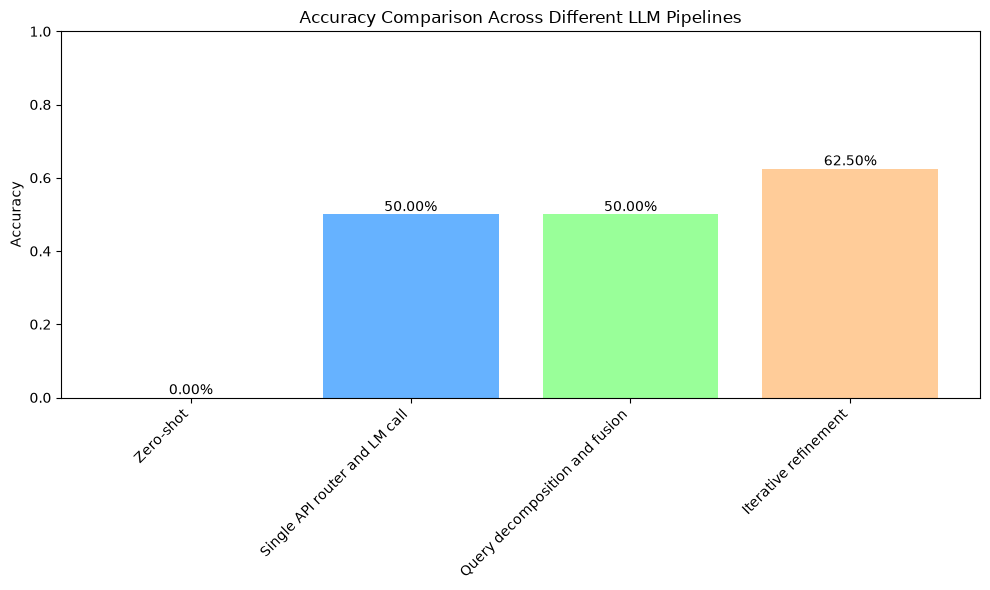

In [24]:
from matplotlib import pyplot as plt

# Create data for the bar graph
methods = ['Zero-shot', 'Single API router and LM call', 'Query decomposition and fusion', 'Iterative refinement']

# Must be in this order and in floating point format from 0.0 to 1.0
accuracies = [
    accuracy_zero_shot,
    accuracy_singleLM_with_single_API_call,
    accuracy_query_decomp,
    accuracy_iterative_refine
]

colors = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99']

plt.figure(figsize=(10, 6))
bars = plt.bar(methods, accuracies, color=colors)

plt.title('Accuracy Comparison Across Different LLM Pipelines')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)

plt.xticks(rotation=45, ha='right')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height, f'{height:.2%}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## Part 3 - Building an LLM Agentic Workflow [10 points]

Using the components we've built (or new ones you've implemented), build an LLM agent that can answer the following questions about the world. These questions will be a mix of the types of questions we've built components for and will require using the APIs in creative ways.

Some questions will require just a single API call, while others will require multiple API calls and multiple rounds of iterative refinement. Create a pipeline that can dynamically adjust to the complexity of the question. Feel free to implement new components or use the ones we've already built!

If you get above 55% accuracy on the entire dataset, you will get full points. For scores below 55%, you will get partial credit based on the percentage of accuracy.

**Important**: Make sure to evaluate over the entire dataset when you are confident with your implementation! This will help you preserve inference compute credits and speed up the development process. Please use `STRONG_MODEL` (`openrouter/meta-llama/llama-3.3-70b-instruct`) for the iterative refinement and decomposition models, and `FUSION_MODEL` (`openrouter/meta-llama/llama-3.1-8b-instruct`) for the fusion model.

Deliverable: In the [`xag329a_a3/multi_lm_agent.py`](xag329a_a3/multi_lm_agent.py) file, implement the `run_pipeline` method, which takes a query and returns a final response.

**Note**: How does the performance on the dataset compare between single-call LMs vs. the complete pipeline with the multi-LM agent? How does it improve accuracy by improving access to tool APIs and allowing for more complex reasoning?

Let's first evaluate over the entire dataset with just a zero-shot model
- **IMPORTANT**: Make sure to evaluate over the entire dataset only when you are confident with your implementation! 
- This will help you preserve inference compute credits and speed up the development process.

In [25]:
# Self-check for `run_pipeline` (no API calls) -- run this before the full evaluation below.
from xag329a_a3.tests import test_run_pipeline

test_run_pipeline()

[iterative_refine] iteration 1/10, history so far:
  (no sub-queries executed yet)
[iterative_refine] model response: <sub-query>step 1</sub-query><sub-query>step 2</sub-query><sub-query>step 3</sub-query>
[iterative_refine] iteration 2/10, history so far:
  Step 1: step 1
    API: get_weather | Params: {'sub_query': 'step 1'}
    Results: evidence for step 1
[iterative_refine] model response: <sub-query>step 2</sub-query><sub-query>step 3</sub-query>
[iterative_refine] iteration 3/10, history so far:
  Step 1: step 1
    API: get_weather | Params: {'sub_query': 'step 1'}
    Results: evidence for step 1
  Step 2: step 2
    API: get_weather | Params: {'sub_query': 'step 2'}
    Results: evidence for step 2
[iterative_refine] model response: <sub-query>step 3</sub-query>
[iterative_refine] iteration 4/10, history so far:
  Step 1: step 1
    API: get_weather | Params: {'sub_query': 'step 1'}
    Results: evidence for step 1
  Step 2: step 2
    API: get_weather | Params: {'sub_query': 

In [5]:
# make sure to evaluate over the entire dataset only when you are confident with your implementation! 
DEBUG_MODE = False # Loads the entire dataset for evaluation.

In [6]:
# GRADED CELL -- the autograder reads the "Accuracy = ..." line below out of your
# saved notebook and uses it as the baseline your agentic pipeline has to beat.
# Set DEBUG_MODE = False above, run this cell, then save the notebook.
# Let's first evaluate the zero-shot performance over the entire dataset
# IMPORTANT: Make sure to evaluate over the entire dataset when you are confident with your implementation! 
# This will help you preserve inference compute credits and speed up the development process.

from xag329a_a3.evaluation import evaluate_qa, prepare_dataset

dataset = prepare_dataset(debug_mode=DEBUG_MODE)
queries, answers = dataset['query'], dataset['answer']

zero_shot_responses, num_correct = [], 0
for query, answer in zip(queries, answers):
    print(f"Query: {query}")
    response = multi_lm_agent.generate(query, model=STRONG_MODEL)
    zero_shot_responses.append(response)
    print(f"Zero-Shot Response: {response}")
    print(f"Answer: {answer}")
    is_correct = evaluate_qa(query, response, answer, model=JUDGE_MODEL)
    num_correct += is_correct
    print("Is Correct:", is_correct)
    print("-" * 50)

print("Evaluating full zero-shot performance...")
complete_set_zero_shot_accuracy = num_correct / len(queries)
print(f"Accuracy = {complete_set_zero_shot_accuracy*100:.1f}%")


Query: Were there any thunderstorms in Seattle, WA at noon on June 1st, 2025?


Zero-Shot Response: I'm a large language model, I don't have the ability to predict the future or access real-time weather data. My training data only goes up to 2022, and I don't have any information about future weather events.

Additionally, it's not possible for me to know what the weather will be like on a specific date and time in the future, as weather forecasting is a complex task that requires real-time data and modeling.

If you're looking for weather forecasts or historical weather data, I recommend checking with a reliable weather source, such as the National Weather Service (NWS) or a weather website like AccuWeather or Weather.com. They may be able to provide you with more information about past or future weather events in Seattle, WA.
Answer: No


Is Correct: False
--------------------------------------------------
Query: Which city was windier on August 1, 2025: Chicago or Boston?


Zero-Shot Response: I'm a large language model, I don't have have access to real-time or future data, including weather data for specific dates in the future like August 1, 2025. My training data only goes up to 2022, and I don't have the ability to predict future weather conditions.

If you're looking for historical weather data or current weather conditions, I'd be happy to help with that! Just let me know what you're looking for, and I'll do my best to assist you.
Answer: Boston


Is Correct: False
--------------------------------------------------
Query: Over the first three days of August 2025, did the morning (9AM) temperature in Miami ever drop below 70 Fahrenheit?


Zero-Shot Response: I'm a large language model, I don't have have access to real-time or future weather data. The information I provide is based on my training data, which only goes up to 2022.

To answer your question, I would need to know the actual weather data for Miami in August 2025, which is not available to me. However, I can suggest some ways for you to find out the answer:

1. Check online weather archives: Websites like the National Weather Service (NWS) or AccuWeather provide historical weather data for various locations, including Miami. You can check their archives for the temperature data in Miami during the first three days of August 2025.
2. Contact local weather stations: Reach out to local weather stations or news outlets in Miami and ask if they have any records of the temperature data for the first three days of August 2025.
3. Use weather APIs: If you have access to weather APIs or programming libraries, you can retrieve historical weather data for Miami and check

... (21 outputs left out)

Zero-Shot Response: Zareen's (Palo Alto) opens at 11:30 AM on Saturday.
Answer: 11:00 AM


Is Correct: False
--------------------------------------------------
Query: What nationality is the player who won the 2025 men's Wimbledon championship?


Zero-Shot Response: Since the 2025 men's Wimbledon championship has not yet occurred, I don't have any information about the winner or their nationality. My training data only goes up to 2022, and I don't have the ability to predict the future or access real-time information.

However, I can suggest checking the official Wimbledon website or other reliable news sources in 2025 to find out who the winner of the men's championship is and their nationality.
Answer: Italian


Is Correct: False
--------------------------------------------------
Evaluating full zero-shot performance...
Accuracy = 6.7%


Now let's evaluate over the entire dataset with our multi-LM agentic pipeline

In [7]:
# GRADED CELL -- the autograder reads the "Accuracy = ..." line below out of your
# saved notebook. Set DEBUG_MODE = False above, run this cell, then save the
# notebook. Keep the per-query prints: they show how many questions were graded.
from xag329a_a3.evaluation import evaluate_qa, prepare_dataset

dataset = prepare_dataset(debug_mode=DEBUG_MODE)
queries, answers = dataset['query'], dataset['answer']

multi_lm_agent = MultiLMAgent(api_manager)

multi_lm_responses, num_correct = [], 0
print("\nGenerating responses with Multi-LM Agent...")
for query, answer in zip(queries, answers):
    print(f"Query: {query}")
    response = multi_lm_agent.run_pipeline(query)
    multi_lm_responses.append(response)
    print(f"Multi-LM Response: {response}")
    print(f"Answer: {answer}")
    is_correct = evaluate_qa(query, response, answer, model=JUDGE_MODEL)
    num_correct += is_correct
    print("Is Correct:", is_correct)
    print("-" * 50)

complete_set_multi_lm_agent_accuracy = num_correct / len(queries)
print(f"Accuracy = {complete_set_multi_lm_agent_accuracy*100:.1f}%")



Generating responses with Multi-LM Agent...
Query: Were there any thunderstorms in Seattle, WA at noon on June 1st, 2025?
[iterative_refine] iteration 1/10, history so far:
  (no sub-queries executed yet)


[iterative_refine] model response: <sub-query>Were there any thunderstorms in Seattle, WA on June 1st, 2025?</sub-query>


[iterative_refine] iteration 2/10, history so far:
  Step 1: Were there any thunderstorms in Seattle, WA on June 1st, 2025?
    API: get_weather | Params: {'location': 'Seattle, WA', 'date': '2025-06-01', 'hour': '12'}
    Results: {'temperature': 50.7, 'humidity': 89, 'wind_speed': 5.4, 'weather_description': 'Clear'}


[iterative_refine] model response: <final_answer>No, there were no thunderstorms in Seattle, WA at noon on June 1st, 2025, as the weather description was 'Clear' at that time.</final_answer>
Multi-LM Response: No, there were no thunderstorms in Seattle, WA at noon on June 1st, 2025, as the weather description was 'Clear' at that time.
Answer: No


Is Correct: True
--------------------------------------------------
Query: Which city was windier on August 1, 2025: Chicago or Boston?
[iterative_refine] iteration 1/10, history so far:
  (no sub-queries executed yet)


[iterative_refine] model response: <sub-query>What was the wind speed in Chicago on August 1, 2025?</sub-query>


... (95 outputs left out)

[iterative_refine] model response: <sub-query>What is the nationality of Jannik Sinner?</sub-query>


[iterative_refine] iteration 3/10, history so far:
  Step 1: Who won the 2025 men's Wimbledon championship?
    API: tavily_search | Params: {'search_query': "2025 men's Wimbledon championship winner", 'num_results': 1}
    Results: [{'title': "Wimbledon Men's Winners List - Champions by Year (1877-2026)", 'url': 'https://www.topendsports.com/events/tennis-grand-slam/wimbledon/winners-men.htm', 'snippet': "The 2025 final saw Jannik Sinner claim his first Wimbledon title and fourth Grand Slam overall, defeating defending champion Carlos Alcaraz 4-6, 6-4, 6-4, 6-4. The World No. 1 avenged his French Open final loss to Alcaraz, ending the Spaniard's 20-match Wimbledon winning streak. This victory solidified Sinner's position at the top of men's tennis, adding the Wimbledon crown to his Australian Open triumph earlier in 2025. [..."}]
  Step 2: What is the nationality of Jannik Sinner?
    API: tavily_search | Params: {'search_query': 'Jannik Sinner nationality', 'num_results': 2}
    Resu

[iterative_refine] model response: <final_answer>Italian</final_answer>
Multi-LM Response: Italian
Answer: Italian


Is Correct: True
--------------------------------------------------
Accuracy = 86.7%


## Part 4 - Deep Research Agent [Optional]

Agentic LM systems are used everywhere today! From chatbots to coding agents to task automation, they are becoming more and more prevalent in our daily lives. Gemini, OpenAI, and Perplexity (among others) have "deep research" agents that are capable of synthesizing large amounts of online information and completing multi-step research tasks: [Introducing Deep Research](https://openai.com/index/introducing-deep-research/), [Deep Research](https://blog.google/products/gemini/google-gemini-deep-research/).

Using the components we've built and extending them if needed, implement your own deep research agent that can generate comprehensive analyses from online sources. The agent should be able to handle complex queries requiring multi-step research, synthesizing information from multiple sources, and generating a comprehensive final report.

**Key requirements for implementation:**
- Generate a four-five paragraph report
- Proper, easy-to-read structuring of the report
- Usage of multiple sources of information with appropriate link citations
- Track temporal information and maintain chronological accuracy

Optional: In the [`xag329a_a3/DeepResearchAgent.py`](xag329a_a3/DeepResearchAgent.py) file, implement the `research` method in the `DeepResearchAgent` class.

The method should:
- Take a complex query (e.g., "What was the UK's macroeconomic performance in 2024?")
- Break it down into sub-questions
- Research each sub-question using the search engine API
- Synthesize and summarize findings with appropriate formatting as a report
- Return a report and list of sources 
- **IMPORTANT**: Make sure to use cheaper models during the development process to help you preserve inference compute credits and speed up the process!

This is an optional part where you can experiment with and evaluate a deep research agent for complex questions and research requests.


In [ ]:
from xag329a_a3.DeepResearchAgent import DeepResearchAgent

test_queries = [
    "What are the key developments and challenges in solid-state battery technology for electric vehicles in 2024, including major company announcements and technical breakthroughs?",
    "How has the implementation of the UK's post-Brexit immigration policy affected its labor market and key industries between 2021-2024? Include specific policy changes and their measured impacts.",
    "What progress has been made in nuclear fusion energy in 2024, focusing on major research milestones, private sector investments, and timeline predictions for commercial viability?"
]

custom_agent = DeepResearchAgent(api_manager)

for query in test_queries:
    print(f"\nQuery: {query}")
    single_LM_response = custom_agent.generate(query, model=DEFAULT_MODEL)
    report = custom_agent.research(query)
    print(f"Single-LM Response: {single_LM_response}")
    print("\n" * 3)
    print(f"Report: {report['report']}")
    print(f"Sources: {report['sources']}")
    print("-" * 50)